# BAN 612 Week 7 — AI-Assisted Analytics and End-to-End Case

**Business context:** A SaaS company wants to use customer, subscription, invoice, usage, support-ticket, and account-note data to decide which customers need retention attention and which customers may be ready for expansion.

**Important idea:** This notebook does **not** ask AI to replace the analyst. Instead, it shows a safer workflow: prepare a clean evidence packet, ask AI for structured hypotheses, and then verify each claim with pandas before making a business recommendation.

## Learning goals

By the end of this practice, you should be able to:

1. prepare an analysis-ready evidence table for an AI-assisted workflow;
2. write a structured prompt that constrains the AI's task;
3. evaluate AI-generated claims against the actual data;
4. convert verified findings into an action table and management memo;
5. explain why AI output should be treated as a hypothesis, not as evidence by itself.

In [1]:
# Core packages used in this notebook.
# pandas: data manipulation
# numpy: numeric operations
# matplotlib: plotting
# textwrap: formatting longer prompt strings for display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from textwrap import dedent

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

## 1. Load the datasets

The Week 7 case continues the SaaS dataset, but adds `account_notes.csv`, which represents short qualitative notes written by account managers. These notes are included so we can discuss how AI might help summarize unstructured text, while still requiring the analyst to validate quantitative claims.

In [3]:
DATA_DIR = "Week5_SaaS_Data"

customers = pd.read_csv(f"{DATA_DIR}/customers.csv")
subscriptions = pd.read_csv(f"{DATA_DIR}/subscriptions.csv")
invoices = pd.read_csv(f"{DATA_DIR}/invoices.csv")
usage = pd.read_csv(f"{DATA_DIR}/weekly_usage.csv")
tickets = pd.read_csv(f"{DATA_DIR}/support_tickets.csv")
notes = pd.read_csv(f"{DATA_DIR}/account_notes.csv")

print("customers", customers.shape)
print("subscriptions", subscriptions.shape)
print("invoices", invoices.shape)
print("usage", usage.shape)
print("tickets", tickets.shape)
print("notes", notes.shape)

customers (140, 7)
subscriptions (158, 8)
invoices (1142, 8)
usage (5928, 7)
tickets (300, 7)
notes (145, 4)


## 2. Convert date columns

Even though Week 5 covered data wrangling, we still need a small amount of preparation here to ensure the case table is ready for analysis.

In [4]:
# Convert date-like columns into datetime values.
# errors="coerce" converts invalid dates into NaT instead of crashing the notebook.
subscriptions["start_date"] = pd.to_datetime(subscriptions["start_date"], errors="coerce")
subscriptions["end_date"] = pd.to_datetime(subscriptions["end_date"], errors="coerce")

invoices["invoice_date"] = pd.to_datetime(invoices["invoice_date"], errors="coerce")
invoices["paid_date"] = pd.to_datetime(invoices["paid_date"], errors="coerce")

usage["week_start"] = pd.to_datetime(usage["week_start"], errors="coerce")

tickets["opened_at"] = pd.to_datetime(tickets["opened_at"], errors="coerce")
tickets["closed_at"] = pd.to_datetime(tickets["closed_at"], errors="coerce")

notes["note_date"] = pd.to_datetime(notes["note_date"], errors="coerce")

## 3. Create a customer-level analytical table

AI tools generally work better when the analyst gives them a well-defined evidence table rather than raw, messy files. The next cells aggregate each source to the customer level.

In [5]:
# Latest subscription record per customer.
# After sorting by customer and start date, tail(1) keeps the most recent record within each customer group.
latest_subscription = (
    subscriptions
    .sort_values(["customer_id", "start_date"])
    .groupby("customer_id", as_index=False)
    .tail(1)
    [["customer_id", "plan_name", "billing_cycle", "mrr", "subscription_status"]]
)

latest_subscription.head()

,customer_id,plan_name,billing_cycle,mrr,subscription_status
0,C1000,Growth,Annual,245.00,Active
1,C1001,Growth,Monthly,207.23,Active
2,C1002,Starter,Monthly,89.78,Churned
3,C1003,Starter,Annual,100.13,Churned
5,C1004,Growth,Monthly,256.86,Active


In [6]:
# Usage summary: average weekly usage per customer.
usage_summary = (
    usage
    .groupby("customer_id", as_index=False)
    .agg(
        avg_active_users=("active_users", "mean"),
        avg_logins=("logins", "mean"),
        avg_reports=("reports_created", "mean"),
        avg_api_calls=("api_calls", "mean"),
        avg_storage_gb=("storage_gb", "mean")
    )
)

usage_summary.head()

,customer_id,avg_active_users,avg_logins,avg_reports,avg_api_calls,avg_storage_gb
0,C1000,7.423077,27.615385,11.692308,594.711538,6.883462
1,C1001,7.288462,26.750000,10.961538,578.250000,6.785000
2,C1002,2.923077,10.410256,2.307692,59.692308,1.412821
3,C1003,3.900000,13.700000,3.600000,72.400000,2.200000
4,C1004,6.826923,25.269231,9.442308,543.250000,6.221731


In [7]:
# Usage trend: compare the most recent 8 weeks with the previous 8 weeks.
# A sharp negative change may indicate declining engagement.
last_week = usage["week_start"].max()
last8_start = last_week - pd.Timedelta(weeks=7)
prev8_start = last8_start - pd.Timedelta(weeks=8)

last8 = (
    usage[usage["week_start"] >= last8_start]
    .groupby("customer_id", as_index=False)
    .agg(logins_last8=("logins", "sum"))
)

prev8 = (
    usage[(usage["week_start"] >= prev8_start) & (usage["week_start"] < last8_start)]
    .groupby("customer_id", as_index=False)
    .agg(logins_prev8=("logins", "sum"))
)

usage_trend = last8.merge(prev8, on="customer_id", how="outer").fillna(0)

usage_trend["login_change_pct"] = np.where(
    usage_trend["logins_prev8"] > 0,
    (usage_trend["logins_last8"] - usage_trend["logins_prev8"]) / usage_trend["logins_prev8"] * 100,
    np.nan
)

usage_trend.head()

,customer_id,logins_last8,logins_prev8,login_change_pct
0,C1000,253.0,192,31.770833
1,C1001,246.0,189,30.158730
2,C1002,0.0,39,-100.000000
3,C1004,238.0,131,81.679389
4,C1005,1219.0,900,35.444444


In [8]:
# Invoice summary.
# Business rule: an invoice is unpaid only if amount_due > 0 AND amount_paid is 0.
invoices["is_unpaid"] = (
    (invoices["amount_due"] > 0) &
    (invoices["amount_paid"].fillna(0) == 0)
)

invoices["days_to_pay"] = (
    invoices["paid_date"] - invoices["invoice_date"]
).dt.days

invoice_summary = (
    invoices
    .groupby("customer_id", as_index=False)
    .agg(
        total_billed=("amount_due", "sum"),
        total_paid=("amount_paid", "sum"),
        unpaid_invoices=("is_unpaid", "sum"),
        avg_days_to_pay=("days_to_pay", "mean"),
        refunds=("refund_amount", "sum")
    )
)

invoice_summary.head()

,customer_id,total_billed,total_paid,unpaid_invoices,avg_days_to_pay,refunds
0,C1000,2646.00,2646.00,0,2.000000,0.00
1,C1001,2341.70,1833.99,2,1.500000,196.87
2,C1002,825.96,659.87,2,1.250000,0.00
3,C1003,1021.33,1021.33,0,0.000000,0.00
4,C1004,3039.04,2576.69,2,7.416667,256.86


In [9]:
# Support-ticket summary.
tickets["time_to_close_days"] = (
    tickets["closed_at"] - tickets["opened_at"]
).dt.total_seconds() / 86400

ticket_summary = (
    tickets
    .groupby("customer_id", as_index=False)
    .agg(
        tickets=("ticket_id", "count"),
        high_priority_tickets=("priority", lambda s: (s == "High").sum()),
        avg_csat=("csat_score", "mean"),
        avg_close_days=("time_to_close_days", "mean")
    )
)

ticket_summary.head()

,customer_id,tickets,high_priority_tickets,avg_csat,avg_close_days
0,C1000,2,1,3.50,2.666667
1,C1001,5,0,2.80,0.500000
2,C1002,4,2,3.75,1.083333
3,C1004,5,1,4.00,0.833333
4,C1005,1,0,4.00,0.166667


In [10]:
# Account-note summary.
# These are deliberately simple counts; a real AI-assisted workflow might summarize note text too.
note_summary = (
    notes
    .groupby("customer_id", as_index=False)
    .agg(
        risk_notes=("note_type", lambda s: (s == "risk").sum()),
        upsell_notes=("note_type", lambda s: (s == "up").sum()),
        notes_count=("note_type", "count")
    )
)

note_summary.head()

,customer_id,risk_notes,upsell_notes,notes_count
0,C1000,0,0,1
1,C1001,1,0,1
2,C1003,1,0,2
3,C1004,1,0,1
4,C1005,0,1,1


In [11]:
# Merge all customer-level summaries into a customer 360 table.
customer360 = (
    customers
    .merge(latest_subscription, on="customer_id", how="left", validate="one_to_one")
    .merge(usage_summary, on="customer_id", how="left", validate="one_to_one")
    .merge(usage_trend[["customer_id", "login_change_pct"]], on="customer_id", how="left", validate="one_to_one")
    .merge(invoice_summary, on="customer_id", how="left", validate="one_to_one")
    .merge(ticket_summary, on="customer_id", how="left", validate="one_to_one")
    .merge(note_summary, on="customer_id", how="left", validate="one_to_one")
)

# Replace missing aggregates with 0 where missing means no observed activity in that source.
fill_zero_cols = [
    "avg_active_users", "avg_logins", "avg_reports", "avg_api_calls", "avg_storage_gb",
    "total_billed", "total_paid", "unpaid_invoices", "refunds",
    "tickets", "high_priority_tickets", "risk_notes", "upsell_notes", "notes_count"
]
customer360[fill_zero_cols] = customer360[fill_zero_cols].fillna(0)

customer360.head()

,customer_id,company_name,signup_date,industry,company_size,region,acquisition_channel,plan_name,billing_cycle,mrr,subscription_status,avg_active_users,avg_logins,avg_reports,avg_api_calls,avg_storage_gb,login_change_pct,total_billed,total_paid,unpaid_invoices,avg_days_to_pay,refunds,tickets,high_priority_tickets,avg_csat,avg_close_days,risk_notes,upsell_notes,notes_count
0,C1000,Evergreen Analytics 0,2024-07-30,Financial Services,51-200,West,Outbound,Growth,Annual,245.00,Active,7.423077,27.615385,11.692308,594.711538,6.883462,31.770833,2646.00,2646.00,0.0,2.000000,0.00,2.0,1.0,3.50,2.666667,0.0,0.0,1.0
1,C1001,Falcon Group 1,2024-12-01,Professional Services,201-1000,South,Referral,Growth,Monthly,207.23,Active,7.288462,26.750000,10.961538,578.250000,6.785000,30.158730,2341.70,1833.99,2.0,1.500000,196.87,5.0,0.0,2.80,0.500000,1.0,0.0,1.0
2,C1002,Civic Partners 2,2024-05-19,Healthcare,51-200,South,Outbound,Starter,Monthly,89.78,Churned,2.923077,10.410256,2.307692,59.692308,1.412821,-100.000000,825.96,659.87,2.0,1.250000,0.00,4.0,2.0,3.75,1.083333,0.0,0.0,0.0
3,C1003,Falcon Systems 3,2024-02-10,Retail,1001+,West,Webinar,Starter,Annual,100.13,Churned,3.900000,13.700000,3.600000,72.400000,2.200000,NaN,1021.33,1021.33,0.0,0.000000,0.00,0.0,0.0,NaN,NaN,1.0,0.0,2.0
4,C1004,Bright Analytics 4,2024-02-08,Professional Services,201-1000,Northeast,Partner,Growth,Monthly,256.86,Active,6.826923,25.269231,9.442308,543.250000,6.221731,81.679389,3039.04,2576.69,2.0,7.416667,256.86,5.0,1.0,4.00,0.833333,1.0,0.0,1.0


## 4. Build interpretable features for decision-making

These features are not machine-learning predictions. They are transparent business indicators that help us ask better questions.

In [12]:
# Value score: percentile rank based on monthly recurring revenue.
# A score near 100 means the customer is among the highest-MRR customers.
customer360["value_score"] = customer360["mrr"].rank(pct=True) * 100

# Usage per dollar: rough efficiency/engagement measure.
customer360["usage_per_dollar"] = customer360["avg_logins"] / (customer360["mrr"] + 1)

# Ticket pressure: support load relative to active users.
customer360["ticket_pressure"] = customer360["tickets"] / (customer360["avg_active_users"] + 1)

# Risk score: transparent heuristic used for teaching.
# Each component reflects a different risk signal.
customer360["risk_score"] = (
    (customer360["login_change_pct"] < -25).astype(int) * 25 +
    (customer360["unpaid_invoices"] > 0).astype(int) * 20 +
    (customer360["avg_csat"] < 3.5).astype(int) * 20 +
    (customer360["high_priority_tickets"] >= 2).astype(int) * 15 +
    (customer360["risk_notes"] > 0).astype(int) * 20
)

customer360[["customer_id", "mrr", "value_score", "login_change_pct", "unpaid_invoices", "avg_csat", "risk_notes", "risk_score"]].head()

,customer_id,mrr,value_score,login_change_pct,unpaid_invoices,avg_csat,risk_notes,risk_score
0,C1000,245.00,46.428571,31.770833,0.0,3.50,0.0,0
1,C1001,207.23,31.428571,30.158730,2.0,2.80,1.0,60
2,C1002,89.78,11.428571,-100.000000,2.0,3.75,0.0,60
3,C1003,100.13,18.571429,NaN,0.0,NaN,1.0,20
4,C1004,256.86,52.857143,81.679389,2.0,4.00,1.0,40


In [13]:
# Segment customers for management action.
customer360["action_segment"] = np.select(
    [
        (customer360["value_score"] >= 70) & (customer360["risk_score"] >= 50),
        (customer360["value_score"] >= 70) & (customer360["risk_score"] < 50),
        (customer360["value_score"] < 70) & (customer360["risk_score"] >= 50)
    ],
    ["Save now", "Expand carefully", "Scaled retention"],
    default="Monitor"
)

customer360["action_segment"].value_counts()

action_segment
Monitor             91
Expand carefully    41
Scaled retention     6
Save now             2
Name: count, dtype: int64

## 5. Visualize the decision map

This is where Weeks 5 and 6 connect to Week 7. Wrangling and EDA create the structured evidence needed for an AI-assisted decision workflow.

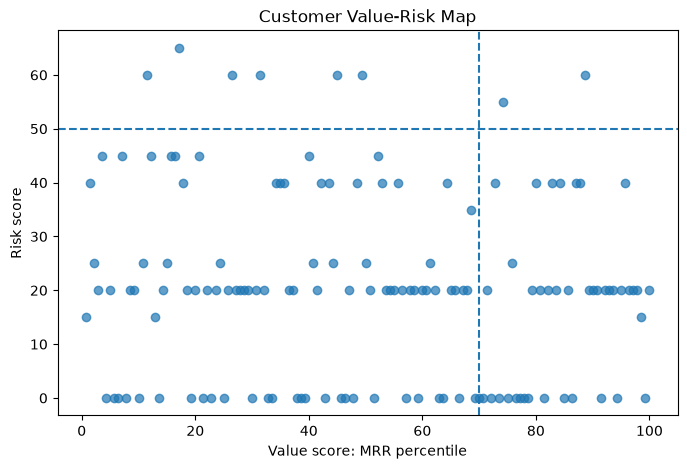

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(customer360["value_score"], customer360["risk_score"], alpha=0.7)
plt.axvline(70, linestyle="--")
plt.axhline(50, linestyle="--")
plt.xlabel("Value score: MRR percentile")
plt.ylabel("Risk score")
plt.title("Customer Value-Risk Map")
plt.show()

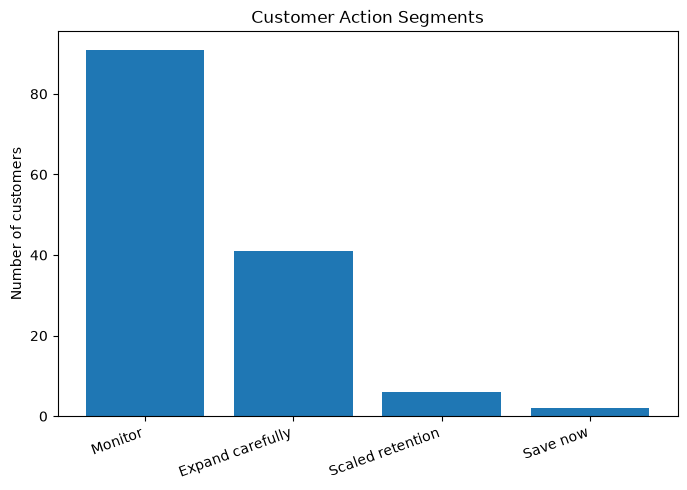

In [15]:
segment_counts = customer360["action_segment"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(segment_counts.index, segment_counts.values)
plt.title("Customer Action Segments")
plt.ylabel("Number of customers")
plt.xticks(rotation=20, ha="right")
plt.show()

## 6. Prepare an AI prompt packet

A safer AI workflow gives the model only the information needed for a specific task and asks for structured output. Notice that the prompt asks for **hypotheses** and requires the model to separate evidence from recommendations.

In [16]:
# Create a compact evidence table for AI review.
# We do not send every raw row; we send a focused, customer-level table.
evidence_cols = [
    "customer_id", "company_name", "industry", "company_size", "region",
    "plan_name", "mrr", "value_score", "avg_active_users", "avg_logins",
    "login_change_pct", "unpaid_invoices", "tickets", "high_priority_tickets",
    "avg_csat", "risk_notes", "upsell_notes", "risk_score", "action_segment"
]

evidence_table = customer360[evidence_cols].copy()

# Limit the prompt packet to customers where some management action may be needed.
focus_table = evidence_table[
    evidence_table["action_segment"].isin(["Save now", "Expand carefully", "Scaled retention"])
].sort_values(["risk_score", "value_score"], ascending=False)

focus_table.head(10)

,customer_id,company_name,industry,company_size,region,plan_name,mrr,value_score,avg_active_users,avg_logins,login_change_pct,unpaid_invoices,tickets,high_priority_tickets,avg_csat,risk_notes,upsell_notes,risk_score,action_segment
61,C1061,Harbor Partners 61,Retail,201-1000,West,Starter,98.20,17.142857,3.312500,12.187500,-30.097087,2.0,3.0,0.0,5.000000,1.0,0.0,65,Scaled retention
108,C1108,Evergreen Partners 108,Manufacturing,1-50,International,Enterprise,1712.17,88.571429,39.531915,136.638298,1.060752,1.0,3.0,1.0,3.333333,1.0,0.0,60,Save now
88,C1088,Orchid Retail 88,Professional Services,1-50,Midwest,Growth,252.54,49.285714,7.173077,28.057692,-6.194690,2.0,2.0,0.0,3.000000,1.0,0.0,60,Scaled retention
89,C1089,Summit Systems 89,Manufacturing,1-50,Midwest,Growth,244.87,45.000000,7.442308,29.365385,-39.931741,1.0,3.0,2.0,3.666667,0.0,0.0,60,Scaled retention
1,C1001,Falcon Group 1,Professional Services,201-1000,South,Growth,207.23,31.428571,7.288462,26.750000,30.158730,2.0,5.0,0.0,2.800000,1.0,0.0,60,Scaled retention
48,C1048,Evergreen Retail 48,Professional Services,51-200,South,Starter,107.21,26.428571,3.211538,11.961538,0.000000,2.0,4.0,0.0,3.250000,1.0,0.0,60,Scaled retention
2,C1002,Civic Partners 2,Healthcare,51-200,South,Starter,89.78,11.428571,2.923077,10.410256,-100.000000,2.0,4.0,2.0,3.750000,0.0,0.0,60,Scaled retention
19,C1019,Summit Labs 19,Manufacturing,51-200,Midwest,Business,710.42,74.285714,10.589744,38.641026,-24.908425,1.0,6.0,2.0,3.333333,0.0,1.0,55,Save now
80,C1080,Orchid Analytics 80,Healthcare,201-1000,South,Enterprise,2029.61,95.714286,39.423077,136.596154,-5.590062,2.0,1.0,1.0,NaN,1.0,0.0,40,Expand carefully
68,C1068,Harbor Works 68,Professional Services,1001+,Northeast,Enterprise,1700.47,87.857143,39.653846,145.980769,9.738134,1.0,0.0,0.0,NaN,1.0,0.0,40,Expand carefully


## prompt 
You are helping a SaaS customer-success team.
Use only the evidence table below. Do not invent facts.

Task:
1. Identify the 3 customers that need the most urgent retention attention.
2. Identify 3 customers that may be expansion candidates.
3. For each recommendation, cite the exact fields that support it.
4. Mention any uncertainty or missing information.

Evidence table:
{prompt_table}

Return your answer in this format:
- Retention candidates
- Expansion candidates
- Uncertainties

## 7. Audit an AI-style response

The next cell contains a simulated AI response. It is intentionally plausible. Your job is not to trust it; your job is to verify it.

Retention candidates:
1. C1041 appears urgent because it is high value and has a risk score above 50.
2. C1083 appears urgent because it has declining logins, unpaid invoices, and low CSAT.
3. C1127 appears urgent because it has the highest MRR in the dataset and several risk notes.

Expansion candidates:
1. C1009 appears promising because it is high value, low risk, and has upsell notes.
2. C1078 appears promising because it is a high-MRR customer with positive usage.
3. C1091 appears promising because it has no tickets and high usage per dollar.

Uncertainties:
- We do not know the renewal date.
- The risk score is a heuristic, not a trained churn model.

## 8. Verify AI claims with pandas

The most important Week 7 habit: AI claims become usable only after we verify them against the data.

In [17]:
# Extract the customer IDs mentioned in the mock AI response.
mentioned_ids = ["C1041", "C1083", "C1127", "C1009", "C1078", "C1091"]

claim_check = customer360.loc[
    customer360["customer_id"].isin(mentioned_ids),
    evidence_cols + ["usage_per_dollar", "ticket_pressure"]
].sort_values("customer_id")

claim_check

,customer_id,company_name,industry,company_size,region,plan_name,mrr,value_score,avg_active_users,avg_logins,login_change_pct,unpaid_invoices,tickets,high_priority_tickets,avg_csat,risk_notes,upsell_notes,risk_score,action_segment,usage_per_dollar,ticket_pressure
9,C1009,Nimbus Works 9,Retail,1-50,West,Growth,237.12,41.428571,6.442308,23.538462,-12.977099,0.0,4.0,0.0,3.333333,0.0,0.0,20,Monitor,0.098851,0.537468
41,C1041,Bright Health 41,Professional Services,1-50,Midwest,Starter,111.65,28.571429,2.923077,10.711538,44.444444,1.0,1.0,0.0,4.000000,0.0,1.0,20,Monitor,0.095087,0.254902
78,C1078,Nimbus Health 78,Financial Services,201-1000,Northeast,Starter,89.50,10.000000,0.000000,0.000000,NaN,0.0,1.0,0.0,4.000000,0.0,0.0,0,Monitor,0.000000,1.000000
83,C1083,Nimbus Group 83,Financial Services,201-1000,West,Starter,100.23,19.285714,0.000000,0.000000,NaN,0.0,2.0,0.0,4.500000,0.0,0.0,0,Monitor,0.000000,2.000000
91,C1091,Nimbus Works 91,Manufacturing,51-200,South,Starter,102.13,21.428571,3.115385,12.019231,25.000000,0.0,1.0,0.0,NaN,0.0,0.0,0,Monitor,0.116544,0.242991
127,C1127,Delta Labs 127,Manufacturing,1-50,South,Business,743.18,76.428571,16.634615,62.326923,-2.495202,0.0,3.0,0.0,4.500000,0.0,0.0,0,Expand carefully,0.083752,0.170120


In [18]:
# Check whether each AI statement is supported by the data.
# This deliberately turns vague language into testable conditions.
claim_audit = pd.DataFrame({
    "claim": [
        "C1041 is high value and risk_score > 50",
        "C1083 has declining logins, unpaid invoices, and low CSAT",
        "C1127 has the highest MRR in the dataset",
        "C1009 is high value, low risk, and has upsell notes",
        "C1078 is a high-MRR customer",
        "C1091 has no tickets"
    ],
    "supported_by_data": [
        bool(((customer360.customer_id == "C1041") & (customer360.value_score >= 70) & (customer360.risk_score > 50)).any()),
        bool(((customer360.customer_id == "C1083") & (customer360.login_change_pct < 0) & (customer360.unpaid_invoices > 0) & (customer360.avg_csat < 3.5)).any()),
        bool(customer360.loc[customer360.customer_id == "C1127", "mrr"].iloc[0] == customer360["mrr"].max()) if (customer360.customer_id == "C1127").any() else False,
        bool(((customer360.customer_id == "C1009") & (customer360.value_score >= 70) & (customer360.risk_score < 50) & (customer360.upsell_notes > 0)).any()),
        bool(((customer360.customer_id == "C1078") & (customer360.value_score >= 70)).any()),
        bool(((customer360.customer_id == "C1091") & (customer360.tickets == 0)).any())
    ]
})

claim_audit

,claim,supported_by_data
0,C1041 is high value and risk_score > 50,False
1,"C1083 has declining logins, unpaid invoices, a...",False
2,C1127 has the highest MRR in the dataset,False
3,"C1009 is high value, low risk, and has upsell ...",False
4,C1078 is a high-MRR customer,False
5,C1091 has no tickets,False


## 9. Build an analyst-verified recommendation table

Instead of copying the AI response, we build a verified recommendation table using the definitions we can defend.

In [19]:
retention_candidates = (
    customer360[customer360["action_segment"].isin(["Save now", "Scaled retention"])]
    .sort_values(["risk_score", "value_score", "mrr"], ascending=False)
    [evidence_cols]
    .head(10)
)

retention_candidates

,customer_id,company_name,industry,company_size,region,plan_name,mrr,value_score,avg_active_users,avg_logins,login_change_pct,unpaid_invoices,tickets,high_priority_tickets,avg_csat,risk_notes,upsell_notes,risk_score,action_segment
61,C1061,Harbor Partners 61,Retail,201-1000,West,Starter,98.20,17.142857,3.312500,12.187500,-30.097087,2.0,3.0,0.0,5.000000,1.0,0.0,65,Scaled retention
108,C1108,Evergreen Partners 108,Manufacturing,1-50,International,Enterprise,1712.17,88.571429,39.531915,136.638298,1.060752,1.0,3.0,1.0,3.333333,1.0,0.0,60,Save now
88,C1088,Orchid Retail 88,Professional Services,1-50,Midwest,Growth,252.54,49.285714,7.173077,28.057692,-6.194690,2.0,2.0,0.0,3.000000,1.0,0.0,60,Scaled retention
89,C1089,Summit Systems 89,Manufacturing,1-50,Midwest,Growth,244.87,45.000000,7.442308,29.365385,-39.931741,1.0,3.0,2.0,3.666667,0.0,0.0,60,Scaled retention
1,C1001,Falcon Group 1,Professional Services,201-1000,South,Growth,207.23,31.428571,7.288462,26.750000,30.158730,2.0,5.0,0.0,2.800000,1.0,0.0,60,Scaled retention
48,C1048,Evergreen Retail 48,Professional Services,51-200,South,Starter,107.21,26.428571,3.211538,11.961538,0.000000,2.0,4.0,0.0,3.250000,1.0,0.0,60,Scaled retention
2,C1002,Civic Partners 2,Healthcare,51-200,South,Starter,89.78,11.428571,2.923077,10.410256,-100.000000,2.0,4.0,2.0,3.750000,0.0,0.0,60,Scaled retention
19,C1019,Summit Labs 19,Manufacturing,51-200,Midwest,Business,710.42,74.285714,10.589744,38.641026,-24.908425,1.0,6.0,2.0,3.333333,0.0,1.0,55,Save now


In [20]:
expansion_candidates = (
    customer360[
        (customer360["action_segment"] == "Expand carefully") &
        (customer360["upsell_notes"] > 0)
    ]
    .sort_values(["value_score", "upsell_notes", "avg_logins"], ascending=False)
    [evidence_cols]
    .head(10)
)

expansion_candidates

,customer_id,company_name,industry,company_size,region,plan_name,mrr,value_score,avg_active_users,avg_logins,login_change_pct,unpaid_invoices,tickets,high_priority_tickets,avg_csat,risk_notes,upsell_notes,risk_score,action_segment
69,C1069,Civic Group 69,Retail,51-200,West,Enterprise,2231.81,100.000000,35.258065,146.387097,7.582938,2.0,4.0,1.0,4.25,0.0,1.0,20,Expand carefully
32,C1032,Nimbus Analytics 32,Healthcare,201-1000,Northeast,Enterprise,2110.12,96.428571,37.750000,135.884615,-4.715447,1.0,2.0,0.0,5.00,0.0,1.0,20,Expand carefully
95,C1095,Delta Analytics 95,Manufacturing,51-200,West,Enterprise,1994.67,95.000000,38.592593,139.962963,16.266945,1.0,3.0,1.0,4.00,0.0,1.0,20,Expand carefully
15,C1015,Civic Health 15,Professional Services,1-50,Northeast,Enterprise,1816.08,90.000000,26.229167,95.104167,10.867398,1.0,5.0,0.0,4.25,0.0,1.0,20,Expand carefully
5,C1005,Harbor Partners 5,Professional Services,1-50,South,Enterprise,1642.61,86.428571,37.288462,145.211538,35.444444,0.0,1.0,0.0,4.00,0.0,1.0,0,Expand carefully
58,C1058,Apex Systems 58,Manufacturing,201-1000,West,Enterprise,1566.56,84.285714,37.000000,139.384615,25.443787,0.0,2.0,0.0,2.00,1.0,1.0,40,Expand carefully
107,C1107,Apex Health 107,Education,201-1000,Northeast,Business,775.64,79.285714,16.255814,61.651163,2.428256,0.0,3.0,0.0,3.00,0.0,1.0,20,Expand carefully
123,C1123,Evergreen Health 123,Healthcare,51-200,Northeast,Business,752.86,78.571429,15.307692,51.750000,-10.833333,0.0,0.0,0.0,NaN,0.0,1.0,0,Expand carefully
49,C1049,Evergreen Group 49,Manufacturing,51-200,West,Business,718.33,75.000000,11.125000,44.937500,NaN,0.0,1.0,0.0,5.00,0.0,1.0,0,Expand carefully
126,C1126,Falcon Retail 126,Financial Services,201-1000,Northeast,Business,700.84,72.857143,8.076923,29.980769,64.444444,1.0,2.0,1.0,3.00,0.0,1.0,40,Expand carefully


## 10. Draft a management memo from verified evidence

The memo below is generated from the tables, not from the mock AI response. This is the pattern students should follow: use AI to help think and draft, but ground the final answer in verified data.

In [ ]:
num_save_now = (customer360["action_segment"] == "Save now").sum()
num_expand = (customer360["action_segment"] == "Expand carefully").sum()
num_scaled = (customer360["action_segment"] == "Scaled retention").sum()

memo = f"""
Management memo draft

The customer base contains {len(customer360)} customers. Based on the transparent value-risk rules,
{num_save_now} customers fall into the Save now segment, {num_scaled} fall into Scaled retention,
and {num_expand} fall into Expand carefully.

Recommended retention focus:
Prioritize customers in the Save now segment because they combine high MRR percentile with multiple risk signals.
The risk score is driven by evidence such as declining logins, unpaid invoices, low CSAT, high-priority tickets,
and account-manager risk notes.

Recommended expansion focus:
Treat Expand carefully customers as possible upsell opportunities, especially when they have upsell notes and low risk scores.
However, the team should check renewal timing, stakeholder changes, product-fit notes, and capacity before making an offer.

Important caution:
This risk score is a transparent heuristic, not a validated churn prediction model. It should be used to prioritize human review,
not to make automatic customer decisions.
"""

print(dedent(memo))

## 11. In-class practice

Use the same dataset and answer these questions:

1. Change the risk threshold from 50 to 40. How many additional customers become retention candidates?
2. Create a stricter expansion rule requiring `upsell_notes > 0`, `risk_score < 30`, and `value_score >= 75`.
3. Write a prompt asking AI to create a 5-bullet customer-success action plan, but include a rule that every bullet must cite a column from the evidence table.
4. Create a claim-audit table for your own AI-style response.
5. Explain one AI output that sounds plausible but would be unsafe to use without additional data.

In [ ]:
# Practice starter code: experiment with a lower risk threshold.
practice = customer360.copy()

practice["retention_candidate_40"] = (
    (practice["risk_score"] >= 40) &
    (practice["value_score"] >= 70)
)

practice["retention_candidate_40"].value_counts()